# 3 · PPO: actor-critic with a trust region

**Notebook 3 of 4** — SFT → REINFORCE → **PPO** → AlphaZero-style MCTS.

REINFORCE (notebook 2) had two expensive habits: every move of a game got the
same noisy return, and every game was used for one gradient pass and thrown
away.  **Proximal Policy Optimisation** (Schulman et al., 2017) keeps the same
ingredients — games against frozen opponents, masked softmax policy, value
head — and changes how a batch is turned into updates:

| | REINFORCE | PPO |
|---|---|---|
| advantage of move $t$ | $G - V(s_t)$ (same $G$ for every move) | GAE(λ): mostly *local* value changes around move $t$ |
| passes over a batch | 1 | several epochs, made safe by a **clipped importance ratio** |
| step size control | learning rate only | clipping + KL early stopping |

Same starting point (`checkpoints/sft.pt`), same opponents, same evaluation
protocol (opponents, game count, opening seed) as notebook 2, so the results
are directly comparable.  Output: `checkpoints/ppo.pt` (best evaluated iterate)
and `results/ppo.json`.

**Runtime:** ~25–35 min on an M4.

In [1]:
import sys, json, time, copy, os
import multiprocessing as mp
from pathlib import Path
import numpy as np, chess, torch, torch.nn.functional as F
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "train" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "train"))
from chesslib.encoding import ACTION_SIZE, planes_to_float
from chesslib.model import (load_checkpoint, save_checkpoint, masked_log_softmax, wdl_to_scalar,
                            default_device, count_params)
from chesslib.rollouts import PolicySampler, play_rollouts, bot_move_fn, summarize
from chesslib.arena import play_match

DEVICE = default_device()
CKPT_DIR = ROOT / "train" / "checkpoints"; CKPT_DIR.mkdir(exist_ok=True)
RESULTS = ROOT / "train" / "results"; RESULTS.mkdir(exist_ok=True)
SFT_PATH = Path(os.environ.get("SFT_CKPT", CKPT_DIR / "sft.pt"))   # notebook 1's output
torch.manual_seed(0); np.random.seed(0)
print("device:", DEVICE, "| start from:", SFT_PATH)

device: mps | start from: /Users/connorswanson/Desktop/projects/chessEngine/train/checkpoints/sft.pt


## 1 · From REINFORCE to PPO

### Reusing a batch: importance sampling
The batch was sampled by the policy *before* the update, $\pi_{\text{old}}$.
After one gradient step we are optimising a slightly different $\pi_\theta$, so
the plain policy-gradient loss is no longer correct.  Importance sampling fixes
the expectation:

$$\nabla J(\theta) \approx \mathbb E_{(s,a)\sim\pi_{\text{old}}}\Big[\,r_t(\theta)\,A_t\,\nabla\log\pi_\theta(a_t\mid s_t)\Big],
\qquad r_t(\theta) = \frac{\pi_\theta(a_t\mid s_t)}{\pi_{\text{old}}(a_t\mid s_t)} .$$

(The gradient of the surrogate $r_t A_t$ is exactly this.)  But the estimate is
only trustworthy while $\pi_\theta$ stays close to $\pi_{\text{old}}$ — far away,
the ratios explode and a handful of samples dominate.

### The clipped surrogate
PPO simply removes the incentive to move far:

$$\mathcal L^{\text{clip}} = -\,\mathbb E_t\Big[\min\big(r_t A_t,\ \mathrm{clip}(r_t, 1-\epsilon, 1+\epsilon)\,A_t\big)\Big].$$

If a good move ($A>0$) has already become $1+\epsilon$ times more likely, or a
bad one ($A<0$) $1-\epsilon$ times less likely, its gradient is zero — the
sample has "done its job" for this batch.  The `min` makes it a pessimistic
bound: clipping never hides a change that makes the objective *worse*.  That is
what lets us run **several epochs** over one batch of games.

Two diagnostics tell us how hard the clip is working: the **clip fraction**
(share of samples with $|r-1|>\epsilon$) and the **approximate KL**
$\mathbb E[(r-1)-\log r]$ between old and new policy.  We stop the epochs early
when the KL exceeds a target — a cheap extra guard.

### BatchNorm and the ratio
$r_t$ must be exactly 1 before the first update; otherwise the clip window is
centred on noise.  In **train mode** BatchNorm normalises with the current
minibatch's statistics (and updates its running averages), so the very same
weights give a different $\pi$ in the update than they did while playing.  We
therefore keep the network in **eval mode** everywhere — rollouts, old
log-probs and updates — so BN is a fixed affine map (its scale/shift still
train).  Section 5 checks this numerically.

## 2 · Per-move advantages with GAE(λ)

We record only the **learner's** positions $s_0, s_1, \dots, s_{T-1}$ — the
opponent's reply is part of the environment's transition from $s_t$ to
$s_{t+1}$.  The value head scores a position from the **side to move**'s
point of view, and at every recorded position the side to move is the
learner, so all $V(s_t)$ share one perspective and **no sign flips** are
needed.  (In self-play, where both sides' positions are recorded, consecutive
positions alternate perspective and you must use $-V(s_{t+1})$.)

Rewards: $r_t = 0$ except after the learner's last move, $r_{T-1} = z$, the
final result for the learner (+1/0/−1), whether the game ended on our move or
on the opponent's reply.  After that there is no next position: $V(s_T) := 0$.
Games cut off at the ply cap are scored as draws, exactly as in evaluation.

$$\delta_t = r_t + \gamma V(s_{t+1}) - V(s_t), \qquad A_t = \sum_{k\ge 0} (\gamma\lambda)^k\,\delta_{t+k}.$$

* **λ = 1** telescopes to $A_t = z - V(s_t)$: REINFORCE with a value baseline.
* **λ = 0** gives the one-step TD error $V(s_{t+1}) - V(s_t)$: "did the
  position get better or worse after my move and the reply?" — very low
  variance, but only as right as the value head.
* In between, λ trades the two; credit for the final result decays with
  distance by $\lambda^k$, so a blunder at move 30 is blamed mostly on moves
  near 30, not on move 3.  γ = 1 (no discounting: a win is a win).

Values come from the rollout (`Trajectory.value`, computed by $\pi_{\text{old}}$'s
network), and advantages are **normalised** to mean 0 / std 1 over the batch,
which makes the clip range and learning rate independent of the reward scale.

The value head is trained on the WDL outcome classes (cross-entropy against
$z$, as in notebooks 1–2); for GAE we use its scalar $V = P(\text{win}) - P(\text{loss})$.

In [2]:
learner = load_checkpoint(SFT_PATH, DEVICE).eval()        # eval mode for the WHOLE notebook (BatchNorm)
reference = load_checkpoint(SFT_PATH, DEVICE).eval()
for p in reference.parameters():
    p.requires_grad_(False)
ref_sampler = PolicySampler(reference, DEVICE, temperature=1.0)
learner_sampler = PolicySampler(learner, DEVICE, temperature=1.0)
OPPONENTS = {"sft": ref_sampler, "ab1": bot_move_fn("ab1", seed=1), "heuristic": bot_move_fn("heuristic", seed=1)}
print(f"{count_params(learner):,} parameters")

def gae(traj, lam, gamma=1.0):
    assert traj.learner_color is not None, "self-play would need a sign flip between plies"
    v = np.asarray(traj.value, np.float32)                 # V_old(s_t), learner's view
    T = len(v)
    r = np.zeros(T, np.float32); r[-1] = traj.learner_score()
    v_next = np.append(v[1:], 0.0)                         # V(s_T) := 0 (terminal)
    delta = r + gamma * v_next - v
    adv = np.zeros(T, np.float32); acc = 0.0
    for t in reversed(range(T)):
        acc = delta[t] + gamma * lam * acc
        adv[t] = acc
    return adv

564,331 parameters


## 3 · Batch construction and the PPO update

In [3]:
# CONFIG — the knobs that matter
ITERS = 60
TRAIN_OPPONENTS = {"sft": 48, "ab1": 16}   # same mix as notebook 2
LR = 5e-5
PPO_EPOCHS = 4             # passes over each batch
MINIBATCH = 512
CLIP = 0.2                 # ε
GAE_LAMBDA = 0.95
VALUE_COEF = 0.5
ENTROPY_COEF = 0.001       # small on purpose (see notebook 2, section 7)
KL_COEF = 0.05             # β, KL(π_θ || π_SFT) — same anchor as notebook 2
TARGET_KL = 0.02           # early-stop the epochs when approx KL(old||new) > 1.5 × this
MAX_GRAD_NORM = 1.0
EVAL_EVERY = 10
EVAL_GAMES = 60
EVAL_SEED = 7              # identical evaluation openings to notebook 2
FINAL_GAMES, FINAL_SEED = 100, 99
WORKERS = 4
WARMUP_ROUNDS = 2          # critic warm-up batches (value head only), as in notebook 2

In [4]:
def make_batch(trajs, lam=GAE_LAMBDA):
    trajs = [t for t in trajs if len(t.choice)]
    legal = [l.astype(np.int64) for t in trajs for l in t.legal]
    choice = [c for t in trajs for c in t.choice]
    mask = np.zeros((len(legal), ACTION_SIZE), bool)
    mask[np.repeat(np.arange(len(legal)), [len(l) for l in legal]), np.concatenate(legal)] = True
    z = np.concatenate([t.returns() for t in trajs]).astype(np.float32)   # outcome, learner's view
    adv = np.concatenate([gae(t, lam) for t in trajs])
    v_old = np.concatenate([t.value for t in trajs]).astype(np.float32)
    return {"x": np.stack([p for t in trajs for p in t.planes]),
            "mask": mask,
            "action": np.array([l[c] for l, c in zip(legal, choice)]),
            "logp_old": np.concatenate([t.logp for t in trajs]).astype(np.float32),  # from the sampler
            "adv": adv, "adv_n": ((adv - adv.mean()) / (adv.std() + 1e-8)).astype(np.float32),
            "ret": adv + v_old, "v_old": v_old, "z": z,
            "wdl": (1 - z).astype(np.int64)}

def to_device(batch, idx):
    out = {k: torch.from_numpy(np.ascontiguousarray(v[idx])) for k, v in batch.items() if k != "x"}
    out["x"] = planes_to_float(batch["x"][idx])
    return {k: v.to(DEVICE) for k, v in out.items()}

def forward(model, mb):
    logits, wdl = model(mb["x"])
    logp_all = masked_log_softmax(logits, mb["mask"])                  # log π over LEGAL moves
    return logp_all, logp_all.gather(1, mb["action"][:, None]).squeeze(1), wdl

@torch.no_grad()
def logp_of(model, batch, chunk=512):
    return torch.cat([forward(model, to_device(batch, np.arange(s, min(s + chunk, len(batch["action"])))))[1].cpu()
                      for s in range(0, len(batch["action"]), chunk)]).numpy()

def collect(it_seed, opponents):
    trajs, by_opp = [], {}
    for j, (name, n) in enumerate(opponents.items()):
        tr = play_rollouts(learner_sampler, n, OPPONENTS[name], seed=10_000 * it_seed + j)   # same seeds as nb 2
        by_opp[name] = summarize(tr); trajs += tr
    return trajs, by_opp

opt = torch.optim.Adam([p for p in learner.parameters() if p.requires_grad], lr=LR)

def ppo_update(batch, rng):
    M = len(batch["action"]); logs = []; stopped = False
    steps_per_epoch = (M + MINIBATCH - 1) // MINIBATCH
    for epoch in range(PPO_EPOCHS):
        perm = rng.permutation(M)
        for s in range(0, M, MINIBATCH):
            mb = to_device(batch, perm[s:s + MINIBATCH])
            logp_all, logp, wdl = forward(learner, mb)
            log_ratio = logp - mb["logp_old"]
            ratio = log_ratio.exp()
            with torch.no_grad():
                approx_kl = ((ratio - 1) - log_ratio).mean().item()
                clip_frac = ((ratio - 1).abs() > CLIP).float().mean().item()
            if approx_kl > 1.5 * TARGET_KL:                        # policy moved far enough for this batch
                stopped = True; break
            A = mb["adv_n"]
            policy_loss = -torch.min(ratio * A, ratio.clamp(1 - CLIP, 1 + CLIP) * A).mean()
            value_loss = F.cross_entropy(wdl, mb["wdl"])
            probs = logp_all.exp()
            entropy = -(probs * logp_all).sum(1).mean()
            with torch.no_grad():
                ref_logp_all = masked_log_softmax(reference(mb["x"])[0], mb["mask"])
            kl_ref = (probs * (logp_all - ref_logp_all)).sum(1).mean()
            loss = policy_loss + VALUE_COEF * value_loss - ENTROPY_COEF * entropy + KL_COEF * kl_ref
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(learner.parameters(), MAX_GRAD_NORM)
            opt.step()
            logs.append({"policy_loss": policy_loss.item(), "value_loss": value_loss.item(),
                         "entropy": entropy.item(), "kl_ref": kl_ref.item(),
                         "approx_kl": approx_kl, "clip_frac": clip_frac})
        if stopped:
            break
    out = {k: float(np.mean([l[k] for l in logs])) if logs else float("nan")
           for k in ("policy_loss", "value_loss", "entropy", "kl_ref", "approx_kl", "clip_frac")}
    out["final_approx_kl"] = approx_kl
    out["epochs"] = len(logs) / steps_per_epoch
    out["steps"] = len(logs)
    out["early_stop"] = stopped
    return out

## 4 · Critic warm-up and what GAE does with it

GAE leans on the value head much more than REINFORCE does, and the SFT value
head was trained on the teacher's games, not on learner-vs-opponent games.
Exactly as in notebook 2, we first fit the **value head alone** (trunk and
policy frozen, so the policy is still exactly SFT) on two batches of games.

In [5]:
def warmup_critic(model, rounds, epochs=3, lr=1e-3):
    head = [p for n, p in model.named_parameters() if n.startswith("value")]
    vopt = torch.optim.Adam(head, lr=lr)
    rng_w = np.random.default_rng(1)
    for r in range(rounds):
        b = make_batch(collect(900 + r, TRAIN_OPPONENTS)[0])
        for _ in range(epochs):
            perm = rng_w.permutation(len(b["action"]))
            for s in range(0, len(perm), 512):
                mb = to_device(b, perm[s:s + 512])
                loss = F.cross_entropy(model(mb["x"])[1], mb["wdl"])
                vopt.zero_grad(); loss.backward(); vopt.step()
        print(f"warm-up round {r + 1}: value loss on its last minibatch {loss.item():.3f} "
              f"(uniform guess: ln 3 = {np.log(3):.3f})")

t = time.time()
warmup_critic(learner, WARMUP_ROUNDS)
print(f"{time.time() - t:.0f}s")

warm-up round 1: value loss on its last minibatch 0.524 (uniform guess: ln 3 = 1.099)


warm-up round 2: value loss on its last minibatch 0.596 (uniform guess: ln 3 = 1.099)
25s


What do the advantages of a single game look like now?  One lost game, three
values of λ:

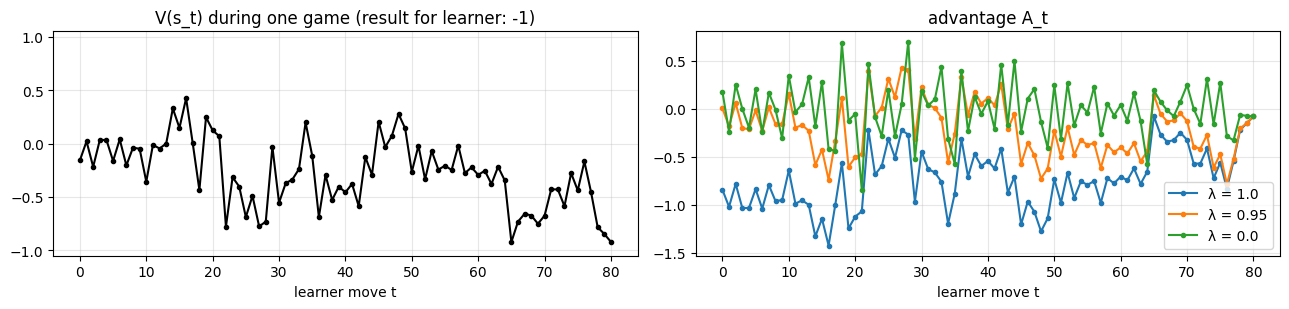

In [6]:
demo = play_rollouts(learner_sampler, 8, ref_sampler, seed=3)
game = max((t for t in demo if t.learner_score() < 0), key=lambda t: len(t.choice), default=demo[0])
fig, ax = plt.subplots(1, 2, figsize=(13, 3.2))
ax[0].plot(game.value, "k.-"); ax[0].set_title(f"V(s_t) during one game (result for learner: {game.learner_score():+.0f})")
ax[0].set_xlabel("learner move t"); ax[0].set_ylim(-1.05, 1.05)
for lam in (1.0, 0.95, 0.0):
    ax[1].plot(gae(game, lam), ".-", label=f"λ = {lam}")
ax[1].set_title("advantage A_t"); ax[1].set_xlabel("learner move t"); ax[1].legend()
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

With λ = 1 every move shares the same $z - V(s_t)$ shape; with smaller λ the
large advantages concentrate on the moves where the value estimate actually
changed.  (How useful that is depends entirely on how good the value head is:
a value head that misjudges positions hands out credit in the wrong places.)

## 5 · Check: the ratio is 1 before the first update

Collect one batch with the starting policy, then recompute $\log\pi_\theta(a_t\mid s_t)$
with the *training* code path (masked log-softmax, eval-mode BN, minibatches
of 512 instead of the rollout's batches) and compare it with the log-probs the
sampler stored while playing.  Then do the same with a copy of the network in
BatchNorm **train** mode.

In [7]:
check_trajs = play_rollouts(learner_sampler, 32, ref_sampler, seed=5)
check = make_batch(check_trajs)
r_eval = np.exp(logp_of(learner, check) - check["logp_old"])
bn_train = copy.deepcopy(learner).train()          # a copy: train-mode forward passes modify BN running stats
r_train = np.exp(logp_of(bn_train, check) - check["logp_old"]); del bn_train
for name, r in [("BN eval mode (what we use)", r_eval), ("BN train mode", r_train)]:
    print(f"{name:28s}: max |r - 1| = {np.abs(r - 1).max():.2e}   mean |r - 1| = {np.abs(r - 1).mean():.2e}   "
          f"clip fraction at ε={CLIP}: {(np.abs(r - 1) > CLIP).mean():.1%}")
assert np.abs(r_eval - 1).max() < 1e-3, "ratio should be 1 (up to float32 rounding) before any update"

BN eval mode (what we use)  : max |r - 1| = 4.77e-07   mean |r - 1| = 6.31e-08   clip fraction at ε=0.2: 0.0%
BN train mode               : max |r - 1| = 2.04e+00   mean |r - 1| = 1.31e-01   clip fraction at ε=0.2: 17.9%


In eval mode the only difference is float32 rounding (the sampler computed
its log-probs from a different batch of boards).  In train mode the "same"
network disagrees with itself, and a large share of samples would be clipped
before a single gradient step — PPO would be fighting noise instead of
optimising.

## 6 · Evaluation (identical protocol to notebook 2)

In [8]:
EVAL_OPP = {"ab1": {"type": "bot", "name": "ab1"},
            "sft": {"type": "policy", "checkpoint": str(SFT_PATH), "label": "SFT"},
            "heuristic": {"type": "bot", "name": "heuristic"}}
POOL = mp.get_context("spawn").Pool(WORKERS)
TMP_FILES = []

def evaluate(model, tag, opponents=EVAL_OPP, n_games=EVAL_GAMES, seed=EVAL_SEED):
    path = CKPT_DIR / f"tmp_ppo_{tag}.pt"           # unique name: workers cache models by path
    save_checkpoint(path, model); TMP_FILES.append(path)
    me = {"type": "policy", "checkpoint": str(path), "label": f"PPO@{tag}"}
    out = {}
    for name, spec in opponents.items():
        if name == "sft" and tag == "it0":
            out[name] = {"W": 0, "D": 0, "L": 0, "score": 0.5, "terminations": {}}  # SFT vs itself
            continue
        m = play_match(me, spec, n_games, workers=WORKERS, seed=seed, pool=POOL)
        out[name] = {"W": m.wins, "D": m.draws, "L": m.losses, "score": m.score, "terminations": m.terminations}
    return out

def eval_key(ev):
    return (ev["ab1"]["score"] + ev["sft"]["score"]) / 2

evals = [{"iter": 0, "games": 0, **evaluate(learner, "it0")}]

PPO@it0 vs ab1: +3 =14 -43 (score 16.7%, Elo diff -280 ± 131)


PPO@it0 vs heuristic: +48 =12 -0 (score 90.0%, Elo diff +382 ± 187)


## 7 · Training loop

Same structure as notebook 2; only the update differs.  Extra diagnostics:
epochs actually completed (KL early stopping), clip fraction, approximate
KL between consecutive policies, and the **explained variance** of the value
head against the games' actual outcomes, $1 - \mathrm{Var}[z - V]/\mathrm{Var}[z]$
(1 = perfect, ≤ 0 = no better than predicting the mean).  (Measuring it
against the λ-returns instead, as many PPO implementations do, flatters the
critic: those returns are built from $V$ itself.)

In [9]:
rng = np.random.default_rng(0)
history = []
best = {"key": eval_key(evals[0]), "iter": 0, "state": copy.deepcopy(learner.state_dict())}
games_played = 0; grad_steps = 0
t0 = time.time()
for it in range(1, ITERS + 1):
    t = time.time()
    trajs, by_opp = collect(it, TRAIN_OPPONENTS)
    games_played += len(trajs)
    t_play = time.time() - t
    batch = make_batch(trajs)
    ev_var = 1 - np.var(batch["z"] - batch["v_old"]) / max(np.var(batch["z"]), 1e-8)   # critic vs actual outcome
    stats = ppo_update(batch, rng); grad_steps += stats["steps"]
    terms = summarize(trajs)["terminations"]
    rep = terms.get("THREEFOLD_REPETITION", 0) + terms.get("FIVEFOLD_REPETITION", 0)
    history.append({"iter": it, "games": games_played, "grad_steps": grad_steps, "positions": len(batch["action"]),
                    **stats, "explained_var": float(ev_var),
                    "score": {k: v["score"] for k, v in by_opp.items()},
                    "avg_plies": float(np.mean([t.plies for t in trajs])),
                    "repetition_frac": rep / len(trajs), "terminations": terms})
    print(f"it {it:2d} | " + " ".join(f"{k} {v['score']:.0%}" for k, v in by_opp.items()) +
          f" | rep {rep / len(trajs):.0%} len {history[-1]['avg_plies']:.0f} | epochs {stats['epochs']:.1f} "
          f"clip {stats['clip_frac']:.2f} kl {stats['approx_kl']:.4f} | ent {stats['entropy']:.2f} "
          f"klSFT {stats['kl_ref']:.3f} EV {ev_var:+.2f} | {t_play:.0f}s play, {time.time() - t - t_play:.0f}s update")
    if it % EVAL_EVERY == 0 or it == ITERS:
        ev = {"iter": it, "games": games_played, **evaluate(learner, f"it{it}")}
        evals.append(ev)
        if eval_key(ev) > best["key"]:
            best = {"key": eval_key(ev), "iter": it, "state": copy.deepcopy(learner.state_dict())}
        print(f"   eval @ {it}: ab1 {ev['ab1']['score']:.0%}  sft {ev['sft']['score']:.0%}  "
              f"heuristic {ev['heuristic']['score']:.0%}  (best so far: iter {best['iter']})")
print(f"training took {(time.time() - t0) / 60:.1f} min, {grad_steps} gradient steps")

it  1 | sft 59% ab1 0% | rep 17% len 114 | epochs 4.0 clip 0.14 kl 0.0113 | ent 1.56 klSFT 0.010 EV +0.20 | 10s play, 4s update


it  2 | sft 48% ab1 0% | rep 16% len 110 | epochs 4.0 clip 0.06 kl 0.0048 | ent 1.52 klSFT 0.017 EV +0.27 | 10s play, 3s update


it  3 | sft 46% ab1 0% | rep 12% len 112 | epochs 4.0 clip 0.07 kl 0.0057 | ent 1.52 klSFT 0.023 EV +0.15 | 11s play, 3s update


it  4 | sft 56% ab1 6% | rep 17% len 121 | epochs 4.0 clip 0.07 kl 0.0055 | ent 1.54 klSFT 0.035 EV +0.28 | 10s play, 4s update


it  5 | sft 51% ab1 0% | rep 14% len 107 | epochs 4.0 clip 0.06 kl 0.0046 | ent 1.48 klSFT 0.039 EV +0.25 | 10s play, 3s update


it  6 | sft 55% ab1 6% | rep 16% len 117 | epochs 4.0 clip 0.06 kl 0.0051 | ent 1.37 klSFT 0.043 EV +0.27 | 11s play, 4s update


... (68 outputs left out)

it 60 | sft 79% ab1 12% | rep 2% len 102 | epochs 4.0 clip 0.08 kl 0.0067 | ent 1.27 klSFT 0.245 EV +0.41 | 9s play, 3s update


PPO@it60 vs ab1: +10 =17 -33 (score 30.8%, Elo diff -140 ± 99)


PPO@it60 vs SFT: +17 =25 -18 (score 49.2%, Elo diff -6 ± 90)


PPO@it60 vs heuristic: +54 =6 -0 (score 95.0%, Elo diff +512 ± 414)
   eval @ 60: ab1 31%  sft 49%  heuristic 95%  (best so far: iter 20)
training took 15.5 min, 1708 gradient steps


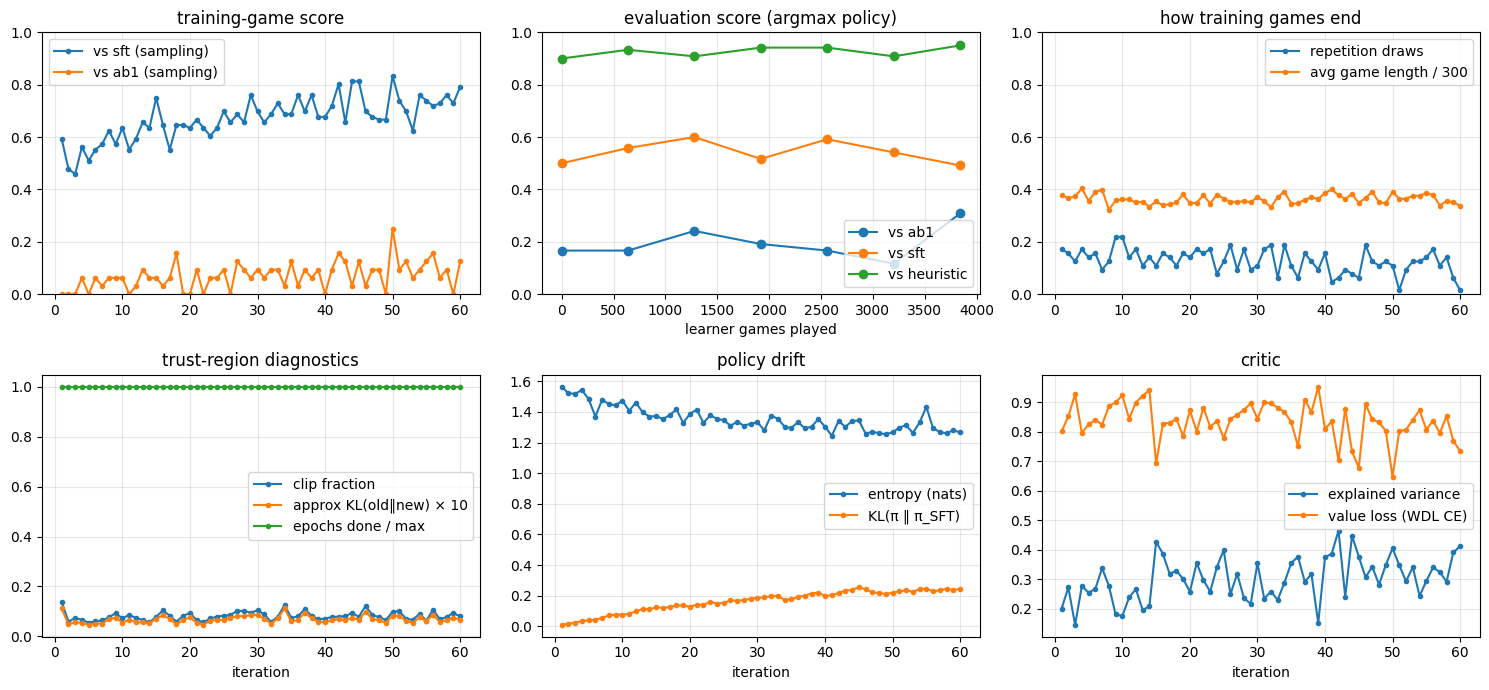

In [10]:
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
it_ = [h["iter"] for h in history]
for name in TRAIN_OPPONENTS:
    ax[0, 0].plot(it_, [h["score"][name] for h in history], ".-", label=f"vs {name} (sampling)")
ax[0, 0].set_title("training-game score"); ax[0, 0].set_ylim(0, 1); ax[0, 0].legend()
g = [e["games"] for e in evals]
for name in EVAL_OPP:
    ax[0, 1].plot(g, [e[name]["score"] for e in evals], "o-", label=f"vs {name}")
ax[0, 1].set_title("evaluation score (argmax policy)"); ax[0, 1].set_xlabel("learner games played")
ax[0, 1].set_ylim(0, 1); ax[0, 1].legend()
ax[0, 2].plot(it_, [h["repetition_frac"] for h in history], ".-", label="repetition draws")
ax[0, 2].plot(it_, [h["avg_plies"] / 300 for h in history], ".-", label="avg game length / 300")
ax[0, 2].set_title("how training games end"); ax[0, 2].set_ylim(0, 1); ax[0, 2].legend()
ax[1, 0].plot(it_, [h["clip_frac"] for h in history], ".-", label="clip fraction")
ax[1, 0].plot(it_, [h["approx_kl"] * 10 for h in history], ".-", label="approx KL(old‖new) × 10")
ax[1, 0].plot(it_, [h["epochs"] / PPO_EPOCHS for h in history], ".-", label="epochs done / max")
ax[1, 0].set_title("trust-region diagnostics"); ax[1, 0].legend()
ax[1, 1].plot(it_, [h["entropy"] for h in history], ".-", label="entropy (nats)")
ax[1, 1].plot(it_, [h["kl_ref"] for h in history], ".-", label="KL(π ‖ π_SFT)"); ax[1, 1].legend()
ax[1, 1].set_title("policy drift")
ax[1, 2].plot(it_, [h["explained_var"] for h in history], ".-", label="explained variance")
ax[1, 2].plot(it_, [h["value_loss"] for h in history], ".-", label="value loss (WDL CE)")
ax[1, 2].set_title("critic"); ax[1, 2].legend()
for a in ax.flat: a.grid(alpha=.3)
for a in ax[1]: a.set_xlabel("iteration")
plt.tight_layout(); plt.show()

## 8 · Best iterate, re-checked on fresh openings
Same procedure as notebook 2: the selected iterate's evaluation score is
optimistically biased, so SFT and the selected iterate replay new openings.

In [11]:
learner.load_state_dict(best["state"])
final_opp = {k: v for k, v in EVAL_OPP.items() if k != "sft"}
sft_model = load_checkpoint(SFT_PATH, "cpu")
final = {"sft": evaluate(sft_model, "final_sft", final_opp, FINAL_GAMES, FINAL_SEED),
         "ppo": evaluate(learner, f"final_best{best['iter']}", EVAL_OPP, FINAL_GAMES, FINAL_SEED)}
final["sft"]["sft"] = {"score": 0.5}
save_checkpoint(CKPT_DIR / "ppo.pt", learner, notebook="chess_ppo", start=str(SFT_PATH),
                best_iter=best["iter"], games_played=games_played)
result = {"config": {"iters": ITERS, "train_opponents": TRAIN_OPPONENTS, "lr": LR, "ppo_epochs": PPO_EPOCHS,
                     "minibatch": MINIBATCH, "clip": CLIP, "gae_lambda": GAE_LAMBDA, "value_coef": VALUE_COEF,
                     "entropy_coef": ENTROPY_COEF, "kl_coef": KL_COEF, "target_kl": TARGET_KL,
                     "warmup_rounds": WARMUP_ROUNDS,
                     "eval_games": EVAL_GAMES, "eval_seed": EVAL_SEED, "start": str(SFT_PATH)},
          "ratio_check": {"eval_max_abs": float(np.abs(r_eval - 1).max()), "train_max_abs": float(np.abs(r_train - 1).max()),
                          "train_clip_frac": float((np.abs(r_train - 1) > CLIP).mean())},
          "history": history, "evals": evals, "best_iter": best["iter"], "final": final}
(RESULTS / "ppo.json").write_text(json.dumps(result, indent=2))
POOL.close(); POOL.join()
for p in TMP_FILES:
    p.unlink(missing_ok=True)
print("saved", CKPT_DIR / "ppo.pt", "(iteration", best["iter"], ")")

PPO@final_sft vs ab1: +9 =19 -72 (score 18.5%, Elo diff -258 ± 92)


PPO@final_sft vs heuristic: +81 =18 -1 (score 90.0%, Elo diff +382 ± 129)


PPO@final_best20 vs ab1: +11 =24 -65 (score 23.0%, Elo diff -210 ± 84)


PPO@final_best20 vs SFT: +23 =54 -23 (score 50.0%, Elo diff -0 ± 69)


PPO@final_best20 vs heuristic: +84 =16 -0 (score 92.0%, Elo diff +424 ± 149)


saved /Users/connorswanson/Desktop/projects/chessEngine/train/checkpoints/ppo.pt (iteration 20 )


## 9 · PPO vs REINFORCE

Both notebooks used the same start, opponents, training-game seeds and
evaluation openings.  The plots show **sample efficiency** (evaluation score
against learner games played); the table compares the selected iterates on the
fresh-opening re-check.

A built-in noise gauge: the two points at 0 games are the *same* SFT policy on
the *same* openings.  Any gap between them comes only from the bots'
randomised move choice (and, for the SFT opponent, is zero by construction) —
gaps of that size between later points mean nothing.

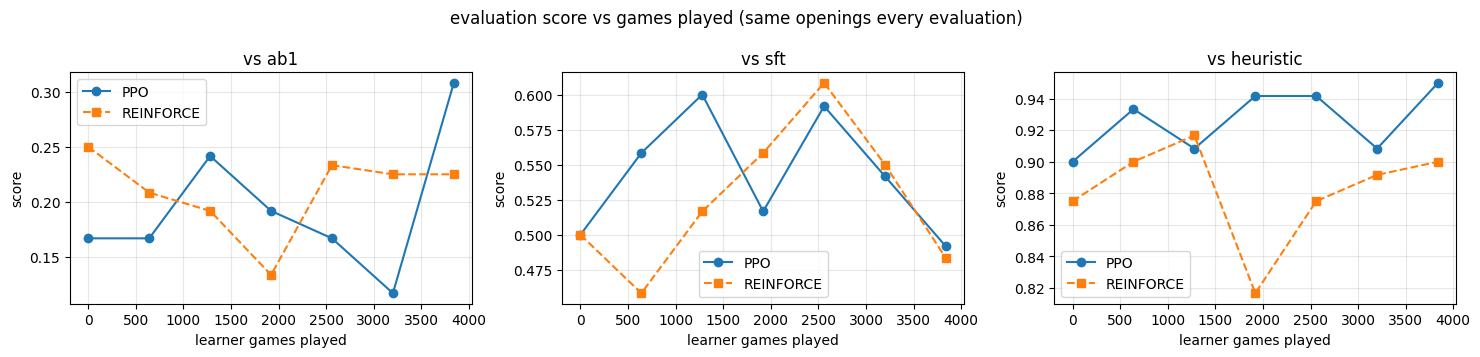

                        vs ab1        vs sft  vs heuristic   (fresh openings, 100 games)
SFT (start)              18.5%         50.0%         90.0%
REINFORCE best           21.5%         44.5%         91.0%
PPO best                 23.0%         50.0%         92.0%

PPO: best iterate 20 / 60, 3840 games, 1708 gradient steps
training-game score vs sft (both sides sampling): first 5 iterations 52% -> last 5 75%
training-game score vs ab1 (both sides sampling): first 5 iterations 1% -> last 5 9%
REINFORCE: best iterate 40 / 60, 3840 games, 239 gradient steps
PPO training games: repetition draws 17% -> 2%, avg length 114 -> 102 plies, entropy 1.56 -> 1.27, KL to SFT 0.245, early-stopped in 0% of iterations
final eval games ending in repetition: vs ab1 14% (SFT) -> 18%, vs heuristic 8% (SFT) -> 7%


In [12]:
rf_path = RESULTS / "reinforce.json"
rf = json.loads(rf_path.read_text()) if rf_path.exists() else None
if rf is None:
    print("results/reinforce.json not found — run chess_reinforce.ipynb first for the comparison.")
elif rf["config"].get("start") != str(SFT_PATH):
    print(f"note: REINFORCE started from {rf['config'].get('start')}, PPO from {SFT_PATH}")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for k, name in enumerate(EVAL_OPP):
    ax[k].plot([e["games"] for e in evals], [e[name]["score"] for e in evals], "o-", label="PPO")
    if rf is not None:
        ax[k].plot([e["games"] for e in rf["evals"]], [e[name]["score"] for e in rf["evals"]], "s--", label="REINFORCE")
    ax[k].set_title(f"vs {name}"); ax[k].set_xlabel("learner games played"); ax[k].set_ylabel("score")
    ax[k].grid(alpha=.3); ax[k].legend()
plt.suptitle("evaluation score vs games played (same openings every evaluation)"); plt.tight_layout(); plt.show()

rows = [("SFT (start)", final["sft"]), ("PPO best", final["ppo"])]
if rf is not None:
    rows.insert(1, ("REINFORCE best", rf["final"]["reinforce"]))
print(f"{'':16s}" + "".join(f"{'vs ' + n:>14s}" for n in EVAL_OPP) + f"   (fresh openings, {FINAL_GAMES} games)")
for label_, fin in rows:
    print(f"{label_:16s}" + "".join(f"{fin[n]['score']:14.1%}" for n in EVAL_OPP))
print(f"\nPPO: best iterate {best['iter']} / {ITERS}, {games_played} games, {grad_steps} gradient steps")
k = min(5, len(history))
for name in TRAIN_OPPONENTS:
    a = np.mean([h["score"][name] for h in history[:k]]); b = np.mean([h["score"][name] for h in history[-k:]])
    print(f"training-game score vs {name} (both sides sampling): first {k} iterations {a:.0%} -> last {k} {b:.0%}")
if rf is not None:
    n_rf_steps = sum(int(np.ceil(h["positions"] / rf["config"]["minibatch"])) for h in rf["history"])
    print(f"REINFORCE: best iterate {rf['best_iter']} / {rf['config']['iters']}, "
          f"{rf['history'][-1]['games']} games, {n_rf_steps} gradient steps")
s0, s1 = history[0], history[-1]
print(f"PPO training games: repetition draws {s0['repetition_frac']:.0%} -> {s1['repetition_frac']:.0%}, "
      f"avg length {s0['avg_plies']:.0f} -> {s1['avg_plies']:.0f} plies, entropy {s0['entropy']:.2f} -> {s1['entropy']:.2f}, "
      f"KL to SFT {s1['kl_ref']:.3f}, early-stopped in {np.mean([h['early_stop'] for h in history]):.0%} of iterations")
def rep_share(ev):
    n = sum(ev["terminations"].values()) or 1
    return (ev["terminations"].get("THREEFOLD_REPETITION", 0) + ev["terminations"].get("FIVEFOLD_REPETITION", 0)) / n
print("final eval games ending in repetition: " + ", ".join(
    f"vs {n} {rep_share(final['sft'][n]):.0%} (SFT) -> {rep_share(final['ppo'][n]):.0%}" for n in final_opp))

## 10 · Strengths and weaknesses

How to read the numbers above: compare each row with **SFT (start)** — a
difference within about ±10 points on 100 games is noise.  The sample-efficiency
plot shows whether PPO got further than REINFORCE *for the same number of
games*; the diagnostics plot shows whether the trust region was active (clip
fraction well above 0, early stops) or idle; explained variance shows whether
the critic was good enough for GAE to give sharper credit than REINFORCE's
$z - V$.  As in notebook 2, compare the training-game score trend (sampling
play) with the argmax evaluation: improvements in the tail of the policy
distribution make sampled play better without necessarily changing the top
move.

**Strengths**
* **Sample reuse.** Several epochs per batch: more learning per (expensive)
  game, with clipping + KL early stopping as the safety net.
* **Sharper credit assignment — if the critic is good.** GAE spreads the
  result over the moves where the value estimate changed instead of over the
  whole game.
* **Stable by construction.** The ratio check, clip fraction and approximate
  KL make it visible when an update goes too far; the same knobs work across
  very different reward scales thanks to advantage normalisation.

**Weaknesses (and why chess is still hard)**
* **The critic is the bottleneck.** GAE's lower variance is paid for with
  bias from $V$.  A value head trained on a few thousand ±1 outcomes is noisy;
  when explained variance is low, λ < 1 hands out credit in the wrong places.
* **Still sparse reward and long horizons.** One number per ~40–80 learner
  moves.  Clipping makes updates *safe*, not *informative*; the information per
  game is the same as for REINFORCE.
* **No lookahead.** The raw policy still plays by instinct; an opponent that
  searches two plies (`ab1`) punishes every tactic the policy hasn't memorised.
* **Exploration by sampling only.** At T = 1 the learner mostly replays moves
  it already likes; it rarely finds a better plan that needs several unusual
  moves in a row.

**Next: notebook 4 (MCTS).**  AlphaZero's answer to all four: run a tree search
at every move (lookahead), and train the policy to match the search's visit
counts — a dense, *per-move* target that is much richer than one game result —
while the value head learns from the outcome.  The policy-gradient machinery
from notebooks 2–3 disappears; the search does the policy improvement.